In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
font = {'size' : 15}
matplotlib.rc('font', **font)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})
from numpy.lib.stride_tricks import sliding_window_view
from skimage import measure
from scipy.spatial import ConvexHull
import os

In [2]:
os.makedirs("plots", exist_ok=True)
fields = [0.13, 0.14, 0.15, 0.16]
fields_colors = matplotlib.colormaps.get('tab10')(range(4))

# Four-point susceptibility $\chi_4$ on the $h(s)$ line
Same definition as in glasses, as used for the elastic line by Russo, Ferrero, Kolton, Rosso, Vandembroucq (arXiv:2604.17600), Eqs. (6)-(7):
$$\pi(\tau)=\frac{1}{L}\sum_{i=0}^{L-1}p_i(\tau), \qquad \chi_4(\tau)=L\left(\langle\pi^{2}(\tau)\rangle_{\rm time}-\langle\pi(\tau)\rangle_{\rm time}^{2}\right)$$
with $p_i(\tau)=1$ if site $i$ stays immobile during $\tau$.

**Sites on the $h(s)$ line.** At time $t_0$ the contour of NB3/NB8 is resampled along $s$ ($ds\le1$); site $i$ is the pixel just outside the front at $\boldsymbol r(s_i)$ (half a pixel along the outward normal), each pixel counted once, so $L(t_0)$ is the number of front pixels. The site is immobile during $\tau$ if its switching frame is $> t_0+\tau$ (never switched, $-1$, counts as immobile). $\langle\cdot\rangle_{\rm time}$ is the average over the origins $t_0$ (every 20 frames), and $\chi_4 = \langle L(t_0)\,(\pi-\bar\pi)^2\rangle_{t_0}$.

**Each field on its own, in 5 windows of $t_0$** (the bubble grows, $L$ and the front speed per frame change). The speed per frame decreases with $R$ (about 8-9 px switched per frame, NB7), so $\pi(\tau;t_0)$ drifts with $t_0$ inside a window: this drift is removed with a quadratic fit in $t_0$ before taking the variance (raw $\chi_4$ dashed in the plot). $t_0 \le T-\tau_{\max}$ so every $\tau$ uses the same origins.

Reference: independent sites with the same $\bar\pi$ give $\chi_4=\bar\pi(1-\bar\pi)$, so $\chi_4/[\bar\pi(1-\bar\pi)]$ is the number of sites (px along the front) that move together. Errors: 95\% bootstrap over 10 contiguous blocks of $t_0$. Time is in frames.

### FUNCTIONS

In [3]:
def segment_noevents(data, no_event_val=-1):
    no_event_regions = [ r.astype('int') for r in measure.find_contours(data,no_event_val)]
    no_event_regions_sizes = np.array([r.shape[0] for r in no_event_regions])
    sorted_regions_idx = np.argsort(no_event_regions_sizes)
    inner_region = no_event_regions[sorted_regions_idx[-2]]
    outer_region = no_event_regions[sorted_regions_idx[-1]]
    center = inner_region.mean(axis=0)
    return inner_region,  outer_region, center

In [4]:
def get_inner_mask(data, inner_region):
    # same as NB3: mask of the inner (initial) domain from the convex hull of inner_region
    nrows, ncols = data.shape
    ii, jj = np.meshgrid(np.arange(0,nrows), np.arange(0,ncols), indexing='ij')
    pts = np.vstack([ii.flatten(), jj.flatten()])
    inner_hull = ConvexHull(inner_region)
    inner_mask = np.ones((nrows, ncols), dtype=bool)
    for eq in inner_hull.equations:
        eq_mask = np.dot(eq[:-1], pts) + eq[-1] <= 1e-12
        inner_mask[ii.flatten(),jj.flatten()] *= eq_mask
    return inner_mask

In [5]:
def get_contour(data, inner_mask, t):
    # same contour as NB3 (sub-pixel, not cast to int), closed, without repeated points
    temp = np.zeros_like(data)
    temp[inner_mask] = 1
    temp[(data > -1)*(data<=t)] = 1
    regions = measure.find_contours(temp)
    r_sizes = [len(r) for r in regions]
    largest_r = regions[np.argmax(r_sizes)]
    largest_r = largest_r[np.r_[True, np.linalg.norm(np.diff(largest_r, axis=0), axis=1) > 0]]
    return largest_r

In [6]:
def resample(line):
    """Uniform arc-length points of one period of the contour, ds = P/N <= 1 (as in NB8)."""
    length = np.r_[0., np.cumsum(np.linalg.norm(np.diff(line, axis=0), axis=1))]
    P = length[-1]
    N = int(np.ceil(P))
    s = np.arange(N)*P/N
    return np.stack((np.interp(s, length, line[:, 0]), np.interp(s, length, line[:, 1])), 1), P/N

In [7]:
def front_sites(data, inner_mask, t):
    # switching frames of the pixels just outside the front at t, ordered along s, each pixel once
    h = get_contour(data, inner_mask, t)
    points, ds = resample(h[:-1])
    tangent = np.roll(points, -1, axis=0) - np.roll(points, 1, axis=0)
    normal = np.stack((-tangent[:,1], tangent[:,0]), 1)
    normal /= np.linalg.norm(normal, axis=1)[:,None]
    nrows, ncols = data.shape
    def outside(normal):
        q = np.rint(points + 0.5*normal).astype(int)
        q[:,0], q[:,1] = np.clip(q[:,0], 0, nrows-1), np.clip(q[:,1], 0, ncols-1)
        return q
    switched = lambda q: inner_mask[q[:,0],q[:,1]] | ((data[q[:,0],q[:,1]] > -1)*(data[q[:,0],q[:,1]] <= t))
    q = outside(normal)
    if switched(q).mean() > 0.5:   # orientation of find_contours
        q = outside(-normal)
    keep = np.r_[True, np.any(q[1:] != q[:-1], axis=1)]
    keep[-1] &= np.any(q[-1] != q[0])
    q = q[keep]
    ts = data[q[:,0],q[:,1]].astype(float)
    ts[ts == -1] = np.inf
    return ts

def chi4_from(PI, L_list, t0_list, detrend=True):
    # chi_4 = < L (pi - pibar)^2 >_t0, pibar = mean over t0 or quadratic trend in t0
    if detrend:
        x = (t0_list - t0_list.mean())/t0_list.std()
        trend = np.vander(x, 3) @ np.polyfit(x, PI, 2)
    else:
        trend = PI.mean(axis=0)
    return (L_list[:,None]*(PI - trend)**2).mean(axis=0)

### EXECUTION

In [8]:
source_folder = "interface_data/"
time_windows = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
taus = np.unique(np.rint(np.geomspace(1, 4000, 32))).astype(int)
dt0 = 20
n_blocks = 10
RNG = np.random.default_rng(20261121)
chi4_dict = {}
for field in fields:
    print(field)
    data = np.loadtxt("data/file_field%1.2f.csv" % field, delimiter=',').astype('int')
    inner_region, outer_region, center = segment_noevents(data)
    inner_mask = get_inner_mask(data, inner_region)
    interface = np.load("%sinterface_field=%1.2f.npz" % (source_folder,field))['interface']
    T = data.max()
    chi4_dict[field] = []
    for f0, f1 in time_windows:
        t0_list = np.arange(max(int(f0*T), dt0), min(int(f1*T), T - taus[-1]), dt0)
        PI, L_list = [], []
        for t0 in t0_list:
            ts = front_sites(data, inner_mask, t0)
            PI.append([ (ts > t0 + tau).mean() for tau in taus])
            L_list.append(len(ts))
        PI, L_list = np.array(PI), np.array(L_list)
        pi = PI.mean(axis=0)
        chi4, chi4_raw = chi4_from(PI, L_list, t0_list), chi4_from(PI, L_list, t0_list, detrend=False)
        blocks = np.array_split(np.arange(len(t0_list)), n_blocks)
        boot = []
        for b in RNG.integers(n_blocks, size=(1000, n_blocks)):
            idx = np.concatenate([blocks[k] for k in b])
            boot.append(chi4_from(PI[idx], L_list[idx], t0_list[idx]))
        R_mean = interface[t0_list, :-1].mean(axis=1)
        chi4_dict[field].append(dict(t0_list=t0_list, R_mean=R_mean, L=L_list.mean(), pi=pi, chi4=chi4, chi4_raw=chi4_raw, chi4_ci=np.percentile(boot, [2.5, 97.5], axis=0)))

0.13


0.14


0.15


0.16


In [9]:
# tau_alpha (pi = 0.5), peak of chi_4 and number of sites moving together at the peak
for field in fields:
    print("H = %1.2f" % field)
    for d in chi4_dict[field]:
        tau_alpha = np.exp(np.interp(-0.5, -d["pi"], np.log(taus)))
        k = np.argmax(d["chi4"])
        print("   t0 in [%5i, %5i]  <R> = %3i-%3i px  L = %4i   tau_alpha = %5.0f   chi4_max = %.2f [%.2f, %.2f] at tau = %4i (pi = %.2f)   raw %.2f   chi4_max/pi(1-pi) = %.1f" % (d["t0_list"][0], d["t0_list"][-1], d["R_mean"][0], d["R_mean"][-1], d["L"], tau_alpha, d["chi4"][k], *d["chi4_ci"][:, k], taus[k], d["pi"][k], d["chi4_raw"].max(), d["chi4"][k]/(d["pi"][k]*(1-d["pi"][k]))))

H = 0.13
   t0 in [   20, 11560]  <R> = 107-198 px  L = 1057   tau_alpha =   290   chi4_max = 4.36 [2.80, 5.13] at tau =  360 (pi = 0.43)   raw 4.86   chi4_max/pi(1-pi) = 17.7
   t0 in [11573, 23133]  <R> = 198-265 px  L = 1563   tau_alpha =   389   chi4_max = 4.35 [1.84, 5.48] at tau =  470 (pi = 0.44)   raw 11.88   chi4_max/pi(1-pi) = 17.7
   t0 in [23146, 34706]  <R> = 265-318 px  L = 1982   tau_alpha =   512   chi4_max = 14.90 [4.43, 17.59] at tau =  803 (pi = 0.35)   raw 15.26   chi4_max/pi(1-pi) = 65.2
   t0 in [34719, 46279]  <R> = 318-358 px  L = 2205   tau_alpha =   585   chi4_max = 9.12 [1.94, 13.71] at tau =  803 (pi = 0.40)   raw 9.91   chi4_max/pi(1-pi) = 38.1
   t0 in [46292, 53852]  <R> = 358-385 px  L = 2722   tau_alpha =   798   chi4_max = 11.61 [3.06, 15.29] at tau = 1050 (pi = 0.43)   raw 40.87   chi4_max/pi(1-pi) = 47.5
H = 0.14
   t0 in [   20, 12060]  <R> =  79-194 px  L =  941   tau_alpha =   212   chi4_max = 3.68 [2.02, 5.26] at tau =  275 (pi = 0.41)   raw 6.94

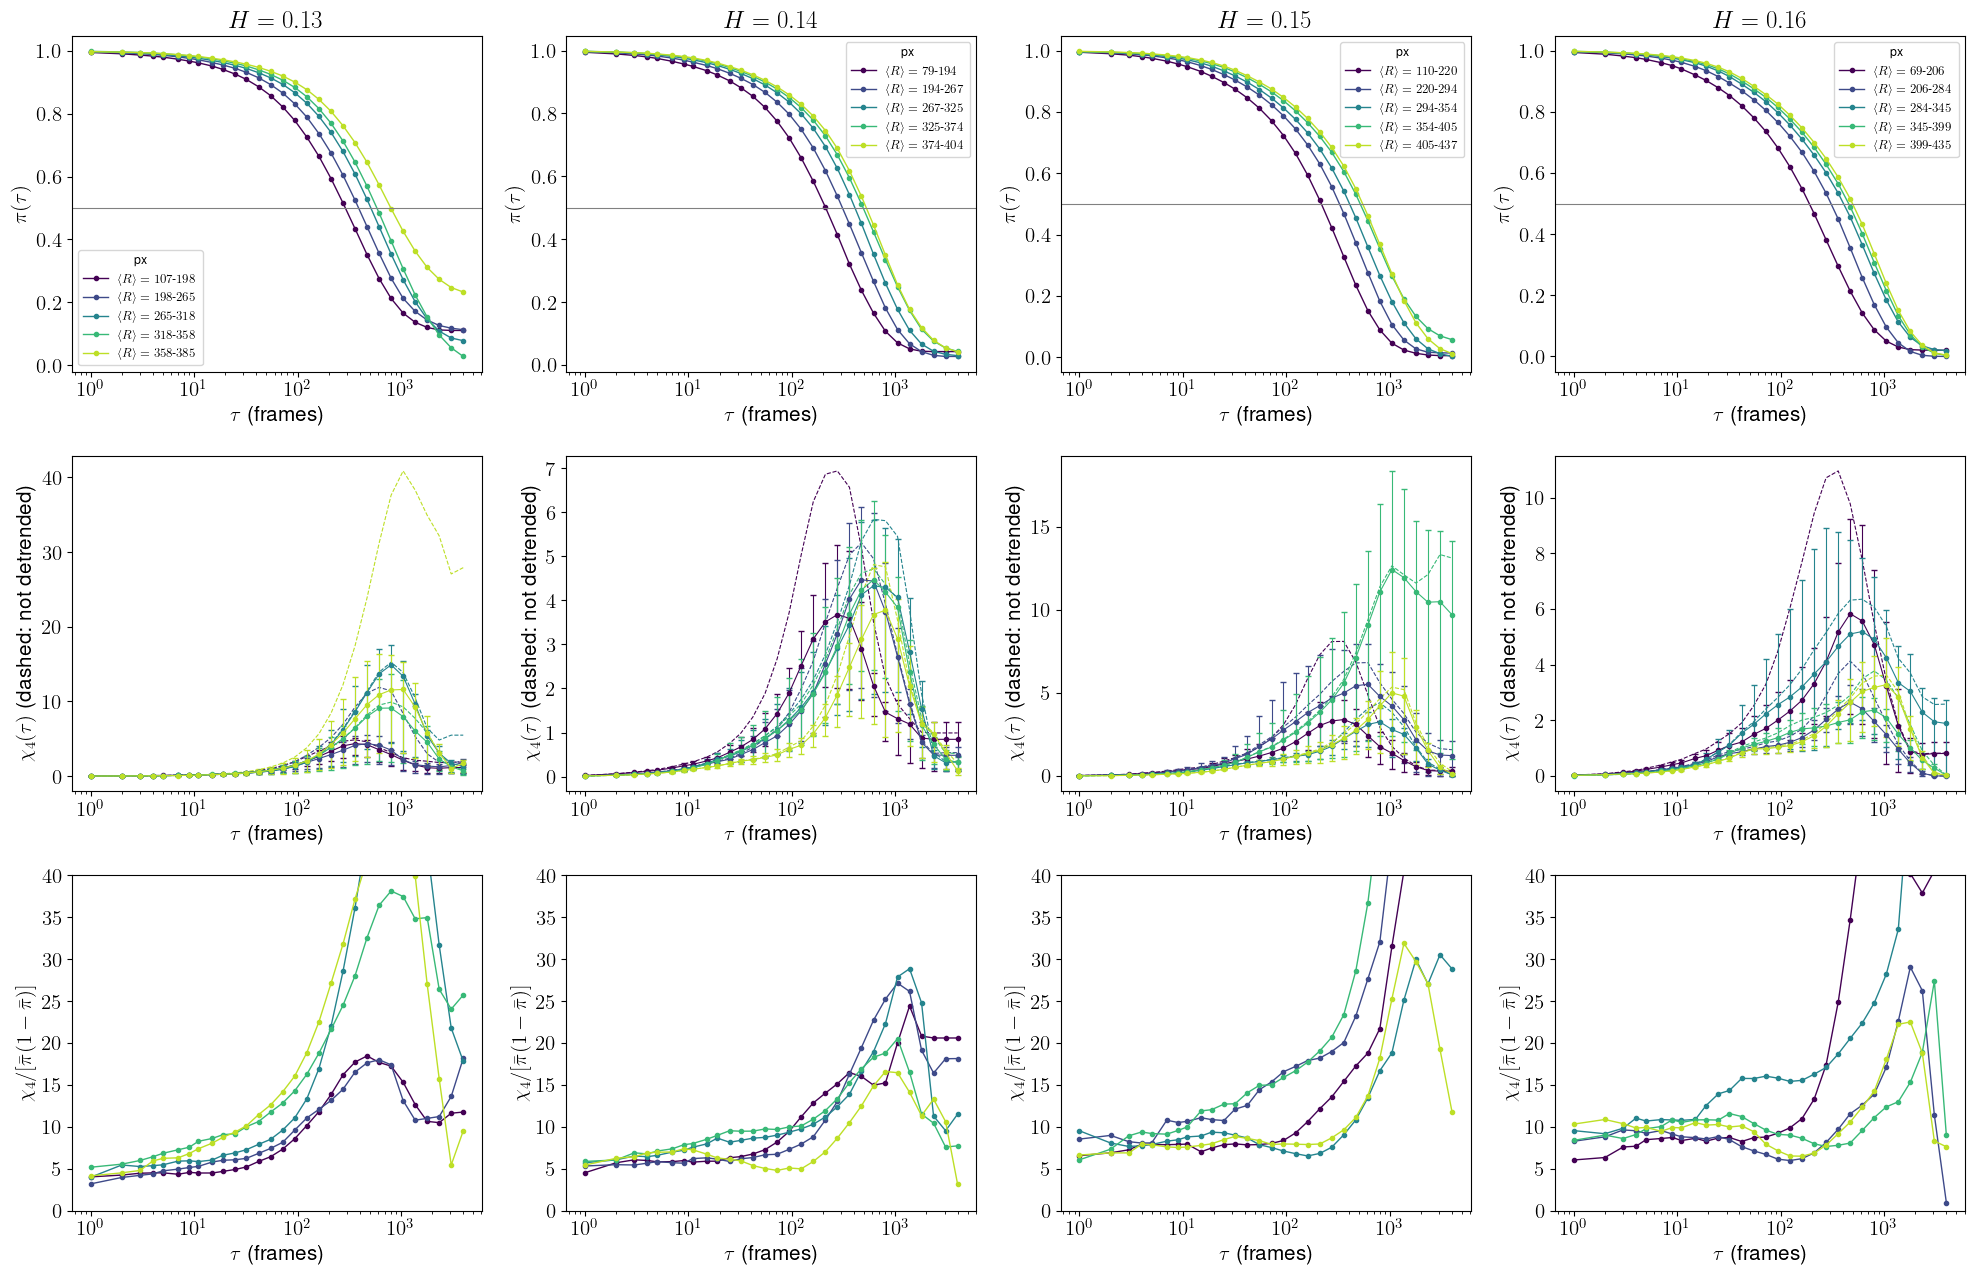

In [10]:
windows_colors = matplotlib.colormaps.get('viridis')(np.linspace(0, 0.9, len(time_windows)))
fig, ax = plt.subplots(figsize=(20,13), ncols=4, nrows=3)
for i, field in enumerate(fields):
    for color, d in zip(windows_colors, chi4_dict[field]):
        lbl = "$\\langle R \\rangle = %i$-$%i$" % (d["R_mean"][0], d["R_mean"][-1])
        ax[0, i].semilogx(taus, d["pi"], marker='o', ms=3, lw=1, color=color, label=lbl)
        ax[1, i].errorbar(taus, d["chi4"], yerr=np.abs(d["chi4_ci"]-d["chi4"]), marker='o', ms=3, capsize=2, lw=0.8, color=color)
        ax[1, i].plot(taus, d["chi4_raw"], ls='--', lw=0.8, color=color)
        ax[2, i].semilogx(taus, d["chi4"]/(d["pi"]*(1-d["pi"])), marker='o', ms=3, lw=1, color=color)
    ax[0, i].axhline(0.5, color='0.5', lw=0.8)
    ax[0, i].set_title("$H=%1.2f$" % field)
    ax[0, i].set_ylabel("$\\pi(\\tau)$")
    ax[0, i].legend(fontsize=9, title="px", title_fontsize=9)
    ax[1, i].set_xscale('log')
    ax[1, i].set_ylabel("$\\chi_4(\\tau)$ (dashed: not detrended)")
    ax[2, i].set_ylabel("$\\chi_4/[\\bar\\pi(1-\\bar\\pi)]$")
    ax[2, i].set_ylim(0, 40)
    for k in range(3):
        ax[k, i].set_xlabel("$\\tau$ (frames)")
plt.tight_layout()
plt.savefig("plots/chi4.pdf", bbox_inches='tight')
plt.show()